In [1]:
import numpy as np
import matplotlib.pyplot as plt

from config import LEARNING_RATE, EPOCHS, NOISE_LEVELS, SEED
from models.hebbian import train_hebbian
from models.associative_memory import train_associative_memory, recall_pattern
from utils.patterns import make_demo_patterns, add_noise
from utils.metrics import recall_accuracy
from utils.plotting import plot_weight_history, show_pattern

np.random.seed(SEED)

### Part A: Hebbian learning

In [2]:
""" Part A – Basic Hebbian Learning

# In this section, you will train a simple Hebbian model on a small correlated dataset.
# You will observe how the weights change across epochs.

"""

# Correlated dataset
X_corr = np.array([
    [1.0, 1.0],
    [0.9, 1.1],
    [1.1, 0.95],
    [1.0, 0.9]
])

# TODO 2:
# Train the Hebbian model using X_corr
# Save the outputs as w_final and history
w_final, history = train_hebbian(X_corr, epochs=EPOCHS, lr=LEARNING_RATE)

print("Final weights:", w_final)

Final weights: [137.28030691 133.5138419 ]


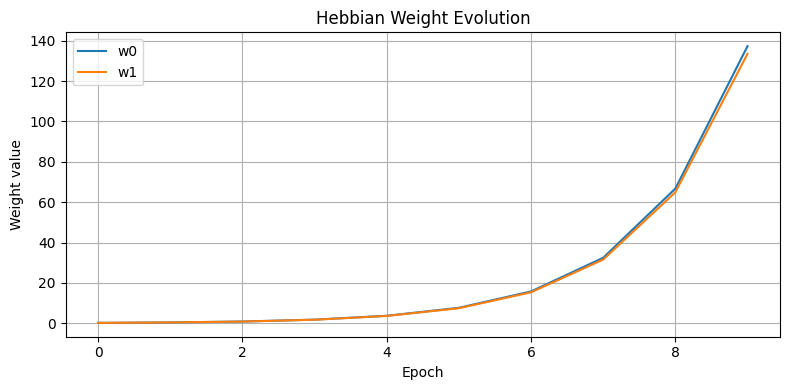

In [3]:
# TODO 3:
# Plot the weight evolution
plot_weight_history(history, title="Hebbian Weight Evolution")

### Part B: Associative memory

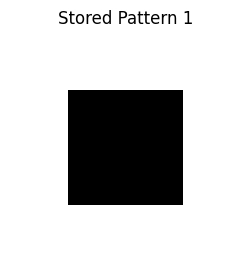

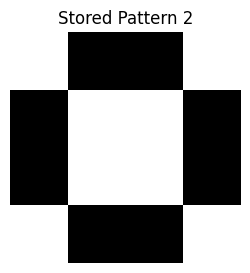

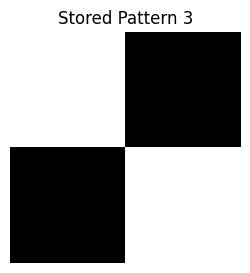

W shape: (16, 16)


In [4]:
"""Part B – Associative Memory

In this section, you will store simple bipolar patterns using Hebbian learning.
Then you will provide a noisy cue and test whether the system can recover the original pattern.

"""
patterns = make_demo_patterns()

for i, p in enumerate(patterns):
    show_pattern(p, title=f"Stored Pattern {i+1}")

# TODO 6:
# Train the associative memory matrix W using the stored patterns
W = train_associative_memory(patterns)

print("W shape:", W.shape)

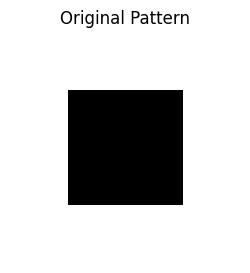

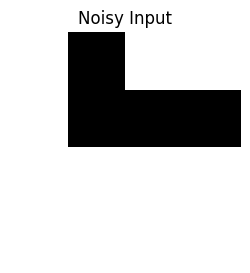

In [5]:
target = patterns[0]
noisy = add_noise(target, noise_level=0.25)

# TODO 7:
# Recall the pattern from the noisy input
# Save it as recalled
recalled = recall_pattern(W, noisy, steps=5)

show_pattern(target, title="Original Pattern")
show_pattern(noisy, title="Noisy Input")

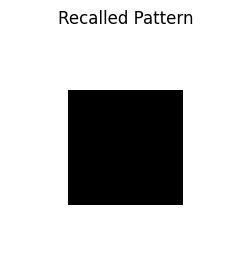

Recall accuracy: 1.0


In [6]:
# TODO 8:
# Display the recalled pattern
# Compute and print recall accuracy
show_pattern(recalled, title="Recalled Pattern")

acc = recall_accuracy(target, recalled)
print("Recall accuracy:", acc)

Section 4 – Noise experiment

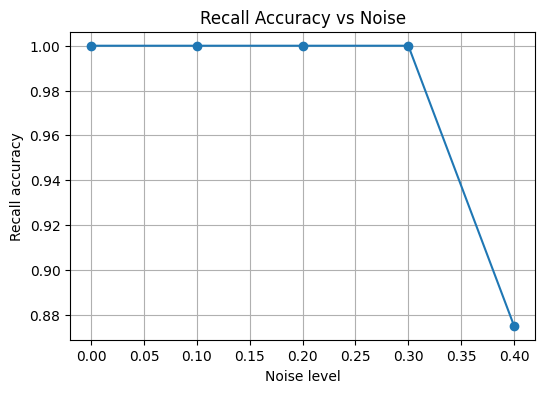

In [7]:
accs = []

for nl in NOISE_LEVELS:
    noisy = add_noise(target, noise_level=nl)
    recalled = recall_pattern(W, noisy, steps=5)
    acc = recall_accuracy(target, recalled)
    accs.append(acc)

plt.figure(figsize=(6,4))
plt.plot(NOISE_LEVELS, accs, marker='o')
plt.xlabel("Noise level")
plt.ylabel("Recall accuracy")
plt.title("Recall Accuracy vs Noise")
plt.grid(True)
plt.show()

Writing Questions
1. Why does Hebbian learning strengthen some connections more than others?
2. What happens to recall performance when noise increases?
3. What is one limitation of Hebbian learning?

**Answers**

**1.** A weight only grows when the input and output are active together (x·y). Inputs that are often active at the same time as the output get bigger updates, so their connections become stronger than the others.

**2.** When noise increases, recall accuracy goes down. Low noise is fixed fully (accuracy 1.0 up to 0.3 noise), but at 0.4 noise too many pixels are flipped and accuracy drops to 0.875.

**3.** The weights keep growing with no limit (unstable). In Part A they went from 0.1 to about 137 in 10 epochs. The memory can also store only a few patterns before they start to mix up.
